<a href="https://colab.research.google.com/github/Cpea8713/IS4487/blob/main/assignment_11_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [ ]:
df = pd.read_csv("cleaned_airbnb_data_7.csv")

print("Rows and columns:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67



Column names:
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'host_url', 'host_name', 'host_since', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'calendar_updated', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', '

### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset includes Airbnb listing information such as price, location, property type, number of bedrooms, availability, reviews, and host information. We can use this information to understand what affects Airbnb prices.

2. The dataset has 459 rows and 77 columns. Each row represents an Airbnb listing, and the columns contain information about the listing.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [ ]:
columns_to_drop = [
    'id', 'listing_url', 'scrape_id', 'last_scraped',
    'source', 'name', 'description',
    'neighborhood_overview', 'host_url', 'host_name',
    'host_about', 'host_thumbnail_url',
    'host_picture_url', 'host_verifications',
    'amenities', 'bathrooms_text', 'license',
    'calendar_updated', 'calendar_last_scraped'
]

df = df.drop(columns=columns_to_drop, errors='ignore')

print("New dataset shape:", df.shape)


New dataset shape: (459, 58)


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I removed columns like listing IDs, URLs, names, descriptions, and other text fields because they don't directly help the regression model predict prices in their current format.

2. Including these columns could introduce unnecessary information and make the model more complicated. Some could also cause errors because linear regression requires numerical inputs.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Strongest correlations with price:
accommodates                   0.579588
beds                           0.547032
bedrooms                       0.499286
bathrooms                      0.468030
review_scores_communication   -0.131798
maximum_maximum_nights         0.122872
longitude                     -0.118913
minimum_maximum_nights         0.112166
maximum_nights_avg_ntm         0.111271
availability_30                0.108409
review_scores_checkin         -0.103223
reviews_per_month             -0.090843
minimum_nights                -0.075122
minimum_minimum_nights        -0.066554
minimum_nights_avg_ntm        -0.065831
Name: price, dtype: float64


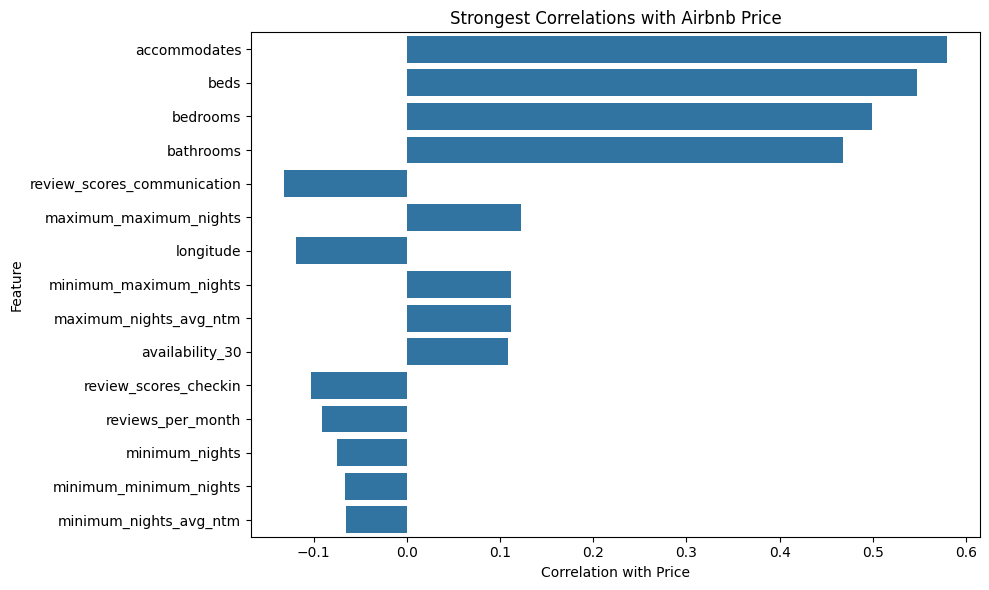

In [ ]:
import numpy as np

df['price'] = pd.to_numeric(
    df['price'].astype(str).str.replace(r'[$,]', '', regex=True),
    errors='coerce'
)

df = df.dropna(subset=['price']).copy()

df = df.drop(columns=['estimated_revenue_l365d'],
             errors='ignore')

numeric_df = df.select_dtypes(include='number')
correlations = numeric_df.corr()

price_correlations = correlations['price'].drop('price')
price_correlations = price_correlations.dropna()
price_correlations = price_correlations.sort_values(
    key=abs, ascending=False
)

print("Strongest correlations with price:")
print(price_correlations.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=price_correlations.head(15).values,
    y=price_correlations.head(15).index
)
plt.title("Strongest Correlations with Airbnb Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The variables with the strongest positive correlations were accommodates, beds, bedrooms, and bathrooms. The strongest negative correlations were review scores for communication and longitude.

2. I think accommodates, beds, bedrooms, and bathrooms would be the most useful predictors because they have the strongest relationships with price.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [ ]:
y = df['price']
X = df.drop(columns=['price'])

X = X.drop(columns=[
    'host_since', 'first_review', 'last_review',
    'host_location', 'host_neighbourhood',
    'neighbourhood', 'neighbourhood_group_cleansed'
], errors='ignore')

X = pd.get_dummies(X, drop_first=True, dtype=int)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

X = X.loc[:, X.nunique() > 1]

print("Target:", y.name)
print("Number of predictors:", X.shape[1])
print("Rows:", X.shape[0])


Target: price
Number of predictors: 133
Rows: 459


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I'm using 133 predictors, including property size, location, bedrooms, bathrooms, and reviews, to predict Airbnb prices.

2. This is a regression problem because we're predicting a numerical value instead of a category.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 367
Testing rows: 92


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("Model trained successfully!")

Model trained successfully!


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

Mean Squared Error (MSE): 6284.18
R-squared (R2): -0.1197


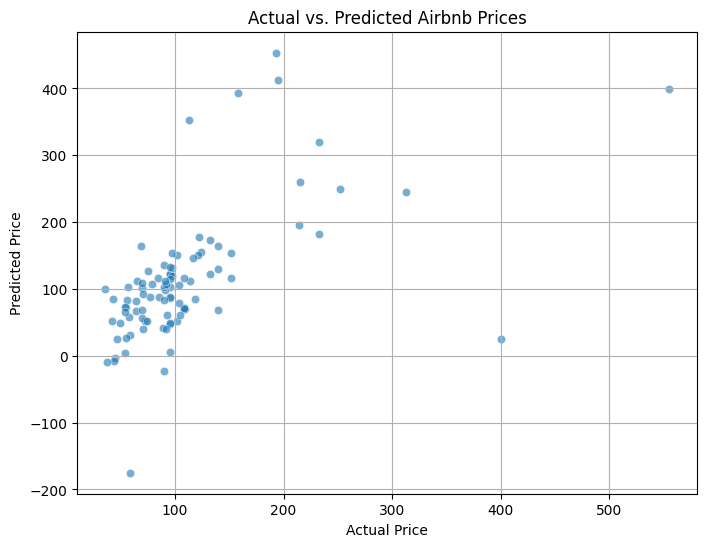

In [ ]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.4f}")

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs. Predicted Airbnb Prices")
plt.grid(True)
plt.show()

### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. My R² score is -0.1197, which means the model does a poor job explaining price variation and performs worse than predicting the average price.

2. My MSE of 6,284.18 is fairly large, showing that the model has significant prediction errors. I could improve it by removing unnecessary features, handling outliers, or trying a different model.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [ ]:
coefficients = pd.Series(
    linear_model.coef_,
    index=X_train.columns
)

coefficients_sorted = coefficients.sort_values(
    key=abs, ascending=False
)

print("Top 15 coefficients:")
print(coefficients_sorted.head(15))


Top 15 coefficients:
host_response_rate_25%                             915.406010
host_acceptance_rate_17%                          -891.360194
host_response_rate_86%                            -649.379529
latitude                                          -392.108461
host_response_rate_60%                             218.711914
property_type_Private room in bed and breakfast   -195.311948
property_type_Entire place                        -189.092361
host_response_rate_97%                             141.403022
longitude                                         -109.030970
host_acceptance_rate_87%                           108.415608
host_acceptance_rate_59%                          -104.483478
host_acceptance_rate_40%                           100.032996
host_acceptance_rate_73%                           -93.742222
property_type_Entire guesthouse                     93.462972
host_acceptance_rate_60%                           -87.866799
dtype: float64


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Host response rate at 25%, host response rate at 60%, and entire-place listings had some of the largest positive impact.

2. Yes, host acceptance rate at 17% and host response rate at 86% had surprisingly large negative impact.

3. The results suggest that host responsiveness and property type may influence pricing, but the large differences in impact make the model difficult to rely on for business decisions.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

Selected features:
['host_response_rate_25%', 'host_acceptance_rate_17%', 'host_response_rate_86%', 'latitude', 'host_response_rate_60%']

Model Comparison:
         Model         MSE  R-squared
Original Model 6284.182364  -0.119676
 Reduced Model 5858.899640  -0.043902


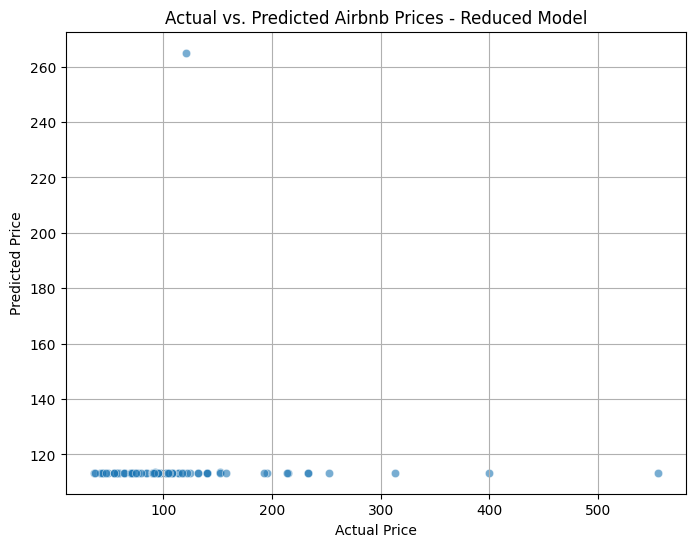

In [ ]:
top_5_features = coefficients.abs().nlargest(5).index

print("Selected features:")
print(top_5_features.tolist())

X_train_reduced = X_train[top_5_features]
X_test_reduced = X_test[top_5_features]

reduced_model = LinearRegression()
reduced_model.fit(X_train_reduced, y_train)

y_pred_reduced = reduced_model.predict(X_test_reduced)

mse_reduced = mean_squared_error(y_test, y_pred_reduced)
r2_reduced = r2_score(y_test, y_pred_reduced)

comparison = pd.DataFrame({
    'Model': ['Original Model', 'Reduced Model'],
    'MSE': [mse, mse_reduced],
    'R-squared': [r2, r2_reduced]
})

print("\nModel Comparison:")
print(comparison.to_string(index=False))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred_reduced, alpha=0.6)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs. Predicted Airbnb Prices - Reduced Model")
plt.grid(True)
plt.show()


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept host response rates of 25%, 86%, and 60%, host acceptance rate of 17%, and latitude because they had the largest absolute coefficients.

2. Yes, the MSE decreased from 6,284.18 to 5,858.90, and R² improved from -0.12 to -0.04. Removing unnecessary features helped, but the model still isn't very accurate.

3. I would choose the reduced model because it performs slightly better and is simpler. However, I would want to improve its accuracy before using it for pricing decisions.

4. This relates to my learning outcome because I want to use regression models to predict property values and make better investment decisions in my house-flipping business.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The model helped explore which Airbnb listing features influence prices and whether we can use those features to predict nightly rates.

2. I would recommend that hosts consider property size, guest capacity, and location when setting prices. I wouldn't rely on this model alone because its predictions aren't accurate enough.

3. I could improve the model by removing outliers, using more relevant features, and trying different regression methods to improve accuracy.

4. This assignment helped me understand how I could use data to predict property prices and identify which features affect value. I could apply this to my house-flipping business to estimate resale prices and potential returns.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 478018 bytes to assignment_11_regression.html
